# AECR-Net


In [1]:
from pathlib import Path
import re
import subprocess
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

METHOD = 'aecrnet'
LABEL = 'AECR-Net'



## Data


In [8]:
# Locate the project when running locally.
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / 'dehazing' / 'methods').is_dir()), None)
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive')
    WORK = Path('/content/dehaze_upstream')
else:
    BASE_DIR = REPO_ROOT or Path.cwd()
    WORK = BASE_DIR / '.dehaze_upstream'

RESIZE = 1600                 # Maximum long edge. Use 800 for O-HAZE-800.
MAX_IMAGES = None                # Set to None to run every pair.
# SRC = BASE_DIR / 'O-HAZE'     # Original dataset with hazy/ and GT/
SRC = Path(r"C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\O-HAZE")
DATA_ROOT = BASE_DIR / (f'O-HAZE-{RESIZE}' if RESIZE > 0 else 'O-HAZE-native')
OUT = BASE_DIR / 'outputs' / METHOD


In [10]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}


def image_index(folder):
    indexed = {}
    for path in sorted(folder.iterdir()):
        if not path.is_file() or path.suffix.lower() not in IMAGE_SUFFIXES:
            continue
        key = re.sub(r'[_-](?:hazy|gt|clear)$', '', path.stem.lower())
        if key in indexed:
            raise ValueError(f'Duplicate image pair key {key}: {indexed[key]} and {path}')
        indexed[key] = path
    return indexed


def paired_images(root):
    hazy = image_index(root / 'hazy')
    gt = image_index(root / 'GT')
    if not hazy or set(hazy) != set(gt):
        raise ValueError(f'{root}: check hazy/ and GT/ pairing. '
                         f'Missing GT: {sorted(hazy.keys() - gt.keys())}; '
                         f'missing hazy: {sorted(gt.keys() - hazy.keys())}')
    return sorted(((hazy[key], gt[key]) for key in hazy), key=lambda pair: pair[0].name)


def read_rgb(path):
    with Image.open(path) as im:
        return im.convert('RGB')


def save_png(image, path):
    pending = path.with_name('.' + path.name + '.part')
    image.save(pending, format='PNG')
    pending.replace(path)


if all((SRC / name).is_dir() for name in ('hazy', 'GT')):
    if SRC.resolve() == DATA_ROOT.resolve():
        raise ValueError('SRC and DATA_ROOT must be separate folders.')
    for name in ('hazy', 'GT'):
        (DATA_ROOT / name).mkdir(parents=True, exist_ok=True)
    for hazy_file, gt_file in paired_images(SRC):
        hazy_out = DATA_ROOT / 'hazy' / (hazy_file.stem + '.png')
        gt_out = DATA_ROOT / 'GT' / (gt_file.stem + '.png')
        if hazy_out.is_file() and gt_out.is_file():
            continue
        hazy = read_rgb(hazy_file)
        scale = min(1.0, RESIZE / max(hazy.size)) if RESIZE > 0 else 1.0
        size = tuple(max(1, round(v * scale)) for v in hazy.size)
        save_png(hazy.resize(size, Image.Resampling.BICUBIC), hazy_out)
        save_png(read_rgb(gt_file).resize(size, Image.Resampling.BICUBIC), gt_out)
elif not all((DATA_ROOT / name).is_dir() for name in ('hazy', 'GT')):
    raise FileNotFoundError(f'Set SRC to an O-HAZE folder with hazy/ and GT/. Checked: {SRC}')

if MAX_IMAGES is not None and MAX_IMAGES < 1:
    raise ValueError('MAX_IMAGES must be positive or None.')
pairs = paired_images(DATA_ROOT)[:MAX_IMAGES]
for hazy_path, gt_path in pairs:
    with Image.open(hazy_path) as hazy, Image.open(gt_path) as gt:
        if hazy.size != gt.size or (RESIZE > 0 and max(hazy.size) > RESIZE):
            raise ValueError(f'Recreate {DATA_ROOT} at the configured RESIZE. Check {hazy_path.name}.')
OUT.mkdir(parents=True, exist_ok=True)
print(f'{len(pairs)} image(s) | Input: {DATA_ROOT} | Output: {OUT}')


5 image(s) | Input: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\O-HAZE-800 | Output: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\outputs\aecrnet


## Pretrained weights
Set `CHECKPOINT` to your `DH_train.pk` file.


In [13]:
# CHECKPOINT = BASE_DIR / 'checkpoints' / 'DH_train.pk'  # Path to the .pk file
CHECKPOINT = Path(r"C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\checkpoint\AECR-Net") / "NH_train.pk"
MODEL_SOURCE = None           # Optional path to the pinned upstream AECR-Net checkout.

import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | Device: {DEVICE}')

def upstream(repo, revision):
    path = WORK / 'upstream' / (repo.replace('/', '--') + '-' + revision[:8])
    if not (path / '.git').is_dir():
        path.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'init', '-q', str(path)], check=True)
    head = subprocess.run(['git', '-C', str(path), 'rev-parse', 'HEAD'],
                          capture_output=True, text=True).stdout.strip()
    if head != revision:
        try:
            subprocess.run(['git', '-C', str(path), 'fetch', '-q', '--depth', '1',
                            'https://github.com/' + repo + '.git', revision], check=True)
            subprocess.run(['git', '-C', str(path), 'checkout', '-q', '--detach', 'FETCH_HEAD'], check=True)
        except subprocess.CalledProcessError as e:
            raise RuntimeError(f'无法获取 {repo}。请检查 Git 和网络连接。') from e
    return path

def load_state(net, path):
    # NumPy 2 moved this helper. Older AECR-Net checkpoints use its NumPy 1 name.
    try:
        from numpy._core.multiarray import scalar as numpy_scalar
    except ImportError:
        from numpy.core.multiarray import scalar as numpy_scalar

    # The training history stores NumPy floating-point metrics alongside the weights.
    metric_types = [
        numpy_scalar,
        (numpy_scalar, 'numpy.core.multiarray.scalar'),
        np.dtype,
        type(np.dtype(np.float32)),
        type(np.dtype(np.float64)),
    ]
    with torch.serialization.safe_globals(metric_types):
        ckpt = torch.load(path, map_location='cpu', weights_only=True)
    for key in ('state_dict', 'model', 'params', 'net'):
        if isinstance(ckpt, dict) and isinstance(ckpt.get(key), dict):
            ckpt = ckpt[key]
            break
    state = {k.removeprefix('module.'): v for k, v in ckpt.items()}
    # The released checkpoint uses the older names for the two feature fusions.
    for old_key, new_key in (('mix4.w', 'mix1.w'), ('mix5.w', 'mix2.w')):
        if old_key in state and new_key not in state:
            state[new_key] = state.pop(old_key)
    net.load_state_dict(state, strict=True)
    print('Weights:', path)
    return net.to(DEVICE).eval()

def tensor_rgb(img):
    return torch.from_numpy(np.array(img, dtype=np.float32) / 255).permute(2, 0, 1)[None].to(DEVICE)

def rgb_array(x):
    return x[0].permute(1, 2, 0).detach().float().cpu().numpy()

if CHECKPOINT is None or not Path(CHECKPOINT).is_file():
    raise FileNotFoundError('请在配置单元把 CHECKPOINT 指向你的 AECR-Net 预训练权重，例如 DH_train.pk。')

import types
from torchvision.ops import DeformConv2d, deform_conv2d
REPO = (Path(MODEL_SOURCE) if MODEL_SOURCE is not None else
        upstream('GlassyWu/AECR-Net', 'd046d0f5f849692ddb6eb6eb3d14f23c86ff5ca6'))



PyTorch 2.8.0+cpu | Device: cpu


## Model


In [15]:
# Match the original DCNv2 parameter names, offsets and sigmoid mask.
class DCN(DeformConv2d):
    def __init__(self, in_channels, out_channels, kernel_size, stride, padding):
        super().__init__(in_channels, out_channels, kernel_size, stride, padding)
        k = self.kernel_size[0] * self.kernel_size[1]
        self.conv_offset_mask = nn.Conv2d(in_channels, 3 * k, kernel_size, stride, padding)

    def forward(self, x):
        o1, o2, mask = self.conv_offset_mask(x).chunk(3, dim=1)
        return deform_conv2d(x, torch.cat((o1, o2), dim=1), self.weight, self.bias,
                             self.stride, self.padding, self.dilation, mask.sigmoid())

def load_source(name, path, replacements=(), extra=None):
    src = path.read_text(encoding='utf-8')
    for before, after in replacements:
        if before not in src:
            raise RuntimeError(f'Expected upstream code missing: {before}')
        src = src.replace(before, after)
    module = types.ModuleType(name)
    if extra:
        module.__dict__.update(extra)
    exec(compile(src, str(path), 'exec'), module.__dict__)
    return module

deconv = load_source('aecr_deconv', REPO / 'models/deconv.py')
aecr = load_source('aecr_model', REPO / 'models/AECRNet.py',
                   [('from deconv import FastDeconv', ''),
                    ('from DCNv2.dcn_v2 import DCN', ''),
                    ('padding=1).cuda()', 'padding=1)')],
                   {'FastDeconv': deconv.FastDeconv, 'DCN': DCN})
net = load_state(aecr.Dehaze(3, 3), Path(CHECKPOINT))


Weights: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\checkpoint\AECR-Net\NH_train.pk


## Method


In [17]:
def dehaze(hazy):
    x = tensor_rgb(hazy)
    h, w = x.shape[-2:]
    x = F.pad(x, (0, max(8, (w+3)//4*4)-w, 0, max(8, (h+3)//4*4)-h), mode='replicate')
    return rgb_array(net(x)[:, :, :h, :w])


## Run over the dataset


In [19]:
for hazy_path, _ in pairs:
    hazy = read_rgb(hazy_path)
    with torch.inference_mode():
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t0 = perf_counter()
        prediction = dehaze(hazy)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        elapsed_ms = (perf_counter() - t0) * 1000
    if prediction.shape != (hazy.height, hazy.width, 3) or not np.isfinite(prediction).all():
        raise ValueError(f'{LABEL}: invalid RGB prediction for {hazy_path.name} ({prediction.shape}).')
    output = Image.fromarray(np.rint(np.clip(prediction, 0, 1) * 255).astype(np.uint8))
    target = OUT / hazy_path.name
    pending = target.with_name('.' + target.stem + '.part' + target.suffix)
    output.save(pending)
    pending.replace(target)
    print(f'{hazy_path.name} | {hazy.width}x{hazy.height} | {elapsed_ms:.1f} ms')


01_outdoor_hazy.png | 741x800 | 7708.2 ms
02_outdoor_hazy.png | 641x800 | 6273.2 ms
03_outdoor_hazy.png | 800x533 | 5022.4 ms
04_outdoor_hazy.png | 663x800 | 6350.2 ms
05_outdoor_hazy.png | 800x632 | 5792.7 ms


## Preview


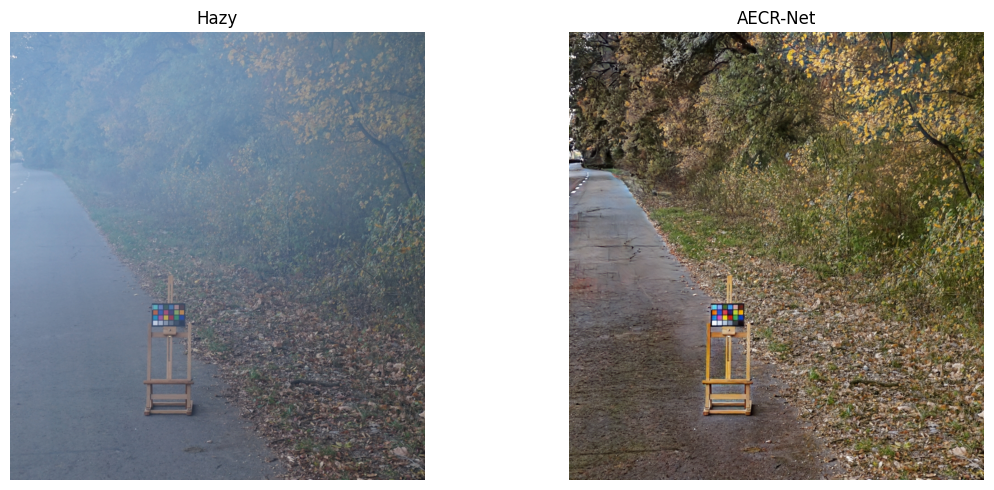

In [21]:
hazy_path, _ = pairs[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, path, title in zip(axes, (hazy_path, OUT / hazy_path.name), ('Hazy', LABEL)):
    ax.imshow(read_rgb(path))
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
